<a href="https://colab.research.google.com/github/Amulya-Kanuparthi/Hurricane-Damage-Analysis-and-Image-Enhancement-Using-Satellite-Imagery/blob/main/GroupE_Phase3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hurricane Damage Analysis and Image Enhancement Using Satellite Imagery
## Phase 3 — Final Pipeline, Independent Evaluation, and Interpretation

**Course:** EDS 6397 — Special Topics: Digital Image Processing  
**Group E:** Amulya Kanuparthi and Adithi Damera  
**Checkpoint:** Phase 3  

This notebook completes the classical pipeline from Phases 1 and 2, freezes parameters on a development set, and evaluates that frozen pipeline on a geographically separate test set. Deep learning is not used.

## 1. Project overview and objective

Hurricane Harvey left building damage that is difficult to see in raw satellite patches because roofs, roads, debris, vegetation, and shadows share similar brightness. Image-level labels exist, but they do not mark which pixels belong to a building.

**Problem.** Improve the visibility of structural boundaries in post-hurricane satellite patches, and measure whether that improvement is real rather than a general increase in edge pixels.

**Objective.** Build a multi-stage enhancement pipeline and test whether it makes meaningful building and road boundaries easier to detect than in the original image.

**Expected outcome.** A reproducible grayscale pipeline, with color retained only as a visual reference, that raises recall of traced structural boundaries and increases the length of long, building-aligned lines. The pipeline is not a damage classifier. A higher edge count is not treated as success.


## 2. Dataset and sample images

**Source.** Kevin Mader, *Satellite Images of Hurricane Damage*, Kaggle, version 1, CC BY 4.0: <https://www.kaggle.com/datasets/kmader/satellite-images-of-hurricane-damage>. The images come from the benchmark in Chen et al., *Benchmark Dataset for Automatic Damaged Building Detection from Post-Hurricane Remotely Sensed Imagery* (<https://arxiv.org/abs/1812.05581>).

**What the files are.** JPEG patches of 128×128 pixels. The file name is `longitude_latitude`. Folders supply an image-level label, `damage` or `no_damage`. Those labels are not pixel masks of buildings, roofs, or debris.

**Characteristics that matter for processing.** Patches are small, JPEG-compressed, and mixed with vegetation, water, and shadows. Grayscale conversion keeps luminance and drops color cues such as floodwater and vegetation. Bright roofs can clip. Damaged and undamaged patches both contain buildings, so an edge map is not a damage map.

**Why the published train/validation split is not used as the experiment split.** Many file names repeat across `train_another`, `validation_another`, and `test`. Nearby patches of the same neighborhood would also leak if one tile were used to choose parameters and a neighbor were used as the test. The audit cell below counts exact coordinate repeats. Parameters are chosen only on the development region defined next, then frozen.

**Study sample (these counts are used everywhere below).**

| Role | Images | damage | no_damage | How it is used |
|---|---:|---:|---:|---|
| Development | 40 | 20 | 20 | Parameter comparison only |
| Independent test | 40 | 20 | 20 | Final evaluation only |
| Boundary reference subset | 8 | 4 | 4 | Eight of the 40 test images, with traced roof and road edges |

Phase 2 reported a separate 20-image development sample and used that same sample both to tune and to quote metrics. Phase 3 does not reuse that design. This notebook does not analyze 20 images, and it does not analyze 200 images.

**Geographic rules.**

- One coordinate is kept once. Search order is `train_another`, `validation_another`, `test`, `test_another`.
- Development region (west Houston): longitude [−95.70, −95.55), latitude [29.70, 29.90).
- Test region (east Houston): longitude [−95.32, −95.12), latitude [29.48, 30.08).
- Every selected patch in a set is at least 0.40 km from every other selected patch, including across the two classes.
- Sampling is greedy after a seeded shuffle of the sorted file list. Seed 6397 is used for `damage` and seed 6398 for `no_damage`.
- The boundary subset is the first four `damage` test paths and the first four `no_damage` test paths in sorted path order.

**Local data.** Place the Kaggle archive so that `train_another` is under `~/Desktop/archive`, or edit `DATA_CANDIDATES` in the next cell. Run the notebook from top to bottom. No path inside the processing functions needs to be edited.


In [ ]:
%matplotlib inline
import math
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import FancyBboxPatch

plt.rcParams.update({
    'figure.dpi': 110,
    'axes.titlesize': 10,
    'axes.labelsize': 9,
    'font.size': 10,
})

print('NumPy', np.__version__, '| OpenCV', cv2.__version__)

# Fixed study design. Do not retune these after looking at the test metrics.
SEED = 6397
N_PER_CLASS = 20
MIN_SEP_KM = 0.40
WEST = (-95.70, -95.55, 29.70, 29.90)   # development: lon_min, lon_max, lat_min, lat_max
EAST = (-95.32, -95.12, 29.48, 30.08)   # independent test
SPLIT_ORDER = ('train_another', 'validation_another', 'test', 'test_another')
FIGURE_DIR = Path.home() / 'Desktop' / 'DIP_Project' / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def find_dataset():
    candidates = [
        Path.home() / 'Desktop' / 'archive',
        Path.cwd() / 'archive',
        Path.cwd().parent / 'archive',
    ]
    for folder in candidates:
        if (folder / 'train_another').is_dir():
            return folder
    searched = '\n'.join(str(p) for p in candidates)
    raise FileNotFoundError(
        'Kaggle archive not found. Download "Satellite Images of Hurricane Damage" '
        'and place it so train_another exists in one of:\n' + searched
    )

DATASET = find_dataset()
print('Dataset root:', DATASET)


NumPy 1.26.4 | OpenCV 4.13.0
Dataset root: /Users/adithidamera/Desktop/archive


In [ ]:
def parse_catalog(root):
    """One record per rounded coordinate. Earlier folders win, so duplicates cannot enter both sets."""
    seen = {}
    for split in SPLIT_ORDER:
        for label in ('damage', 'no_damage'):
            folder = root / split / label
            if not folder.is_dir():
                continue
            for path in folder.iterdir():
                if path.suffix.lower() not in {'.jpg', '.jpeg', '.png'}:
                    continue
                lon, lat = map(float, path.stem.split('_'))
                key = (round(lon, 6), round(lat, 6))
                if key not in seen:
                    seen[key] = (lon, lat, label, f'{split}/{label}/{path.name}')
    return list(seen.values())

def separation_km(a, b):
    """Equirectangular distance in kilometers between two (lon, lat) records."""
    lat_m = math.radians((a[1] + b[1]) / 2)
    dx = math.radians(a[0] - b[0]) * math.cos(lat_m) * 6371.0
    dy = math.radians(a[1] - b[1]) * 6371.0
    return math.hypot(dx, dy)

def sample_region(catalog, box, seed, n_per_class=N_PER_CLASS, min_km=MIN_SEP_KM):
    """Seeded, spatially thinned, class-balanced sample. damage is drawn first."""
    chosen = []
    by_class = {}
    lon0, lon1, lat0, lat1 = box
    for class_index, label in enumerate(('damage', 'no_damage')):
        pool = sorted(
            [rec for rec in catalog
             if rec[2] == label and lon0 <= rec[0] < lon1 and lat0 <= rec[1] < lat1],
            key=lambda rec: rec[3],
        )
        rng = np.random.default_rng(seed + class_index)
        picked = []
        for index in rng.permutation(len(pool)):
            rec = pool[int(index)]
            if all(separation_km(rec, other) >= min_km for other in chosen):
                picked.append(rec)
                chosen.append(rec)
            if len(picked) >= n_per_class:
                break
        if len(picked) < n_per_class:
            raise RuntimeError(f'Only found {len(picked)} {label} images in {box}')
        by_class[label] = picked
    return by_class

def min_pairwise_km(records):
    best = 1e9
    for i, rec in enumerate(records):
        for other in records[i + 1:]:
            best = min(best, separation_km(rec, other))
    return best

catalog = parse_catalog(DATASET)
dev = sample_region(catalog, WEST, SEED)
test = sample_region(catalog, EAST, SEED)
dev_records = dev['damage'] + dev['no_damage']
test_records = test['damage'] + test['no_damage']
annotate_records = sorted(test['damage'], key=lambda rec: rec[3])[:4] + sorted(test['no_damage'], key=lambda rec: rec[3])[:4]

# Published-split leakage audit, reported so the geographic split is justified by this run.
published = {name: set() for name in ('train_another', 'validation_another', 'test')}
for lon, lat, label, rel in catalog:
    split = rel.split('/')[0]
    if split in published:
        published[split].add((round(lon, 6), round(lat, 6)))
# The catalog already dropped duplicate coordinates, so recount from the raw folders.
raw_sets = {}
for split in ('train_another', 'validation_another', 'test'):
    keys = set()
    for label in ('damage', 'no_damage'):
        folder = DATASET / split / label
        for path in folder.iterdir():
            if path.suffix.lower() not in {'.jpg', '.jpeg', '.png'}:
                continue
            lon, lat = map(float, path.stem.split('_'))
            keys.add((round(lon, 6), round(lat, 6)))
    raw_sets[split] = keys

dev_test_km = min(separation_km(a, b) for a in dev_records for b in test_records)
dev_within = min_pairwise_km(dev_records)
test_within = min_pairwise_km(test_records)
overlap_coords = {(round(r[0], 6), round(r[1], 6)) for r in dev_records} & {(round(r[0], 6), round(r[1], 6)) for r in test_records}

print(f'Development images: {len(dev_records)} '
      f'(damage={len(dev["damage"])}, no_damage={len(dev["no_damage"])})')
print(f'Test images:        {len(test_records)} '
      f'(damage={len(test["damage"])}, no_damage={len(test["no_damage"])})')
print(f'Boundary subset:    {len(annotate_records)} '
      f'(damage=4, no_damage=4), all taken from the test set')
print(f'Minimum development–test distance: {dev_test_km:.2f} km')
print(f'Minimum spacing inside development: {dev_within:.3f} km')
print(f'Minimum spacing inside test:        {test_within:.3f} km')
print(f'Shared coordinates between development and test: {len(overlap_coords)}')
print('Coordinates that appear in both published train_another and validation_another:',
      len(raw_sets['train_another'] & raw_sets['validation_another']))
print('Coordinates that appear in both published train_another and test:',
      len(raw_sets['train_another'] & raw_sets['test']))

assert len(dev_records) == 40 and len(test_records) == 40 and len(annotate_records) == 8
assert len(dev['damage']) == len(dev['no_damage']) == len(test['damage']) == len(test['no_damage']) == 20
assert len(overlap_coords) == 0
assert dev_test_km > 30
assert dev_within >= MIN_SEP_KM - 1e-6 and test_within >= MIN_SEP_KM - 1e-6
assert [rec[3] for rec in annotate_records] == [
    'test/damage/-95.24073800000001_29.562787.jpeg',
    'test_another/damage/-95.133131_30.047952000000002.jpeg',
    'test_another/damage/-95.137884_29.987885.jpeg',
    'test_another/damage/-95.140961_29.996931.jpeg',
    'train_another/no_damage/-95.15228499999999_30.028059999999996.jpeg',
    'train_another/no_damage/-95.152913_30.019790000000004.jpeg',
    'train_another/no_damage/-95.156802_30.021576.jpeg',
    'train_another/no_damage/-95.15769499999999_29.755406.jpeg',
]
print('Sample checks passed.')


Development images: 40 (damage=20, no_damage=20)
Test images:        40 (damage=20, no_damage=20)
Boundary subset:    8 (damage=4, no_damage=4), all taken from the test set
Minimum development–test distance: 31.84 km
Minimum spacing inside development: 0.400 km
Minimum spacing inside test:        0.408 km
Shared coordinates between development and test: 0
Coordinates that appear in both published train_another and validation_another: 712
Coordinates that appear in both published train_another and test: 1342
Sample checks passed.


In [ ]:
def load_rgb(rel):
    bgr = cv2.imread(str(DATASET / rel), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(DATASET / rel)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

def load_group(records):
    images = []
    for lon, lat, label, rel in records:
        rgb = load_rgb(rel)
        gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
        images.append({'lon': lon, 'lat': lat, 'label': label, 'rel': rel, 'rgb': rgb, 'gray': gray})
    return images

development = load_group(dev_records)
heldout = load_group(test_records)
annotated = load_group(annotate_records)
print('Loaded development', len(development), '| test', len(heldout), '| annotated', len(annotated))
print('Native shape:', development[0]['rgb'].shape, development[0]['gray'].dtype)


Loaded development 40 | test 40 | annotated 8
Native shape: (128, 128, 3) uint8


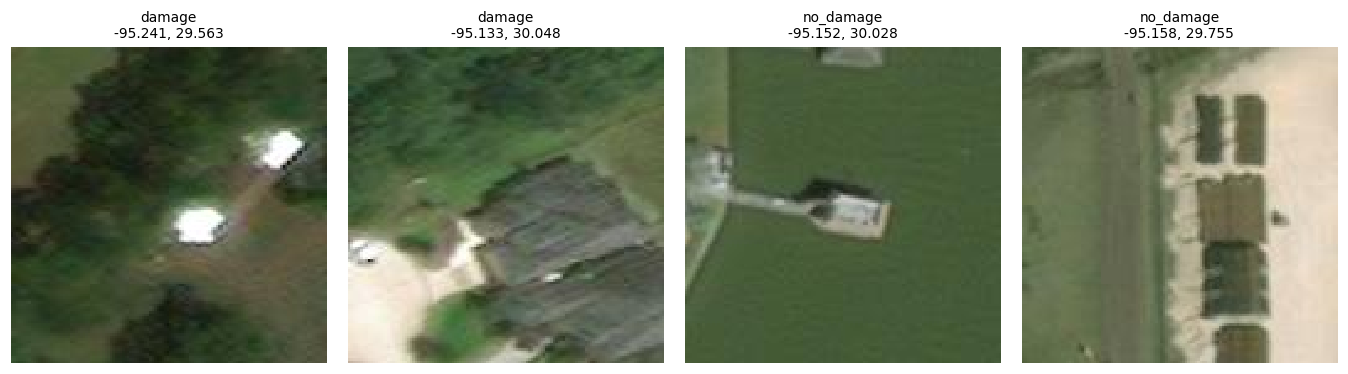

Displayed 4 of the 40 test images. Processing uses the native 128×128 resolution.


In [ ]:
def show_row(items, titles, cmap=None, save_name=None):
    fig, axes = plt.subplots(1, len(items), figsize=(3.1 * len(items), 3.3))
    if len(items) == 1:
        axes = [axes]
    for ax, image, title in zip(axes, items, titles):
        if image.ndim == 2:
            ax.imshow(image, cmap=cmap or 'gray', vmin=0, vmax=255, interpolation='nearest')
        else:
            ax.imshow(image, interpolation='nearest')
        ax.set_title(title, fontsize=9)
        ax.axis('off')
    fig.tight_layout()
    if save_name:
        fig.savefig(FIGURE_DIR / save_name, bbox_inches='tight')
    plt.show()

# Four test patches: two damage, two no_damage. These are display examples.
# Metrics later use all 40 test images, not these four.
examples = [annotated[0], annotated[1], annotated[4], annotated[7]]
show_row(
    [ex['rgb'] for ex in examples],
    [f"{ex['label']}\n{ex['lon']:.3f}, {ex['lat']:.3f}" for ex in examples],
    save_name='01_test_originals.png',
)
print('Displayed 4 of the 40 test images. Processing uses the native 128×128 resolution.')


The four test patches above show the range the pipeline has to handle: bright compact roofs, repetitive building rows, a road beside a roof, and a row of larger rectangular buildings against trees. Vegetation and JPEG blocks are visible in the same patches as the structures of interest.

## 3. Final image processing pipeline

The pipeline uses five technique categories. Frequency-domain filtering stays a diagnostic branch. It is not an input to Canny, because a high-pass detail map has had its brightness removed and would make the edge thresholds depend on an arbitrary display scale. That change was made in Phase 2 and is kept here.

| Order | Category | Technique | Purpose in this project |
|---|---|---|---|
| 1 | Point processing | Percentile contrast stretch, p = 1 | Spreads the midtones so roofs and roads separate from their surroundings, with limited clipping |
| 2 | Histogram processing | CLAHE, clip limit 2, 8×8 tiles | Raises local contrast where a whole patch is bright or dark |
| 3 | Spatial filtering | 3×3 median, then Laplacian sharpening with α = 0.10 | Median limits isolated texture before sharpening; the small Laplacian weight emphasizes boundaries without large halos |
| 4 | Frequency domain | Gaussian high-pass, D₀ = 10, diagnostic only | Shows which fine structure the spatial path is emphasizing |
| 5 | Edge and feature extraction | Gaussian smooth (3×3, σ = 0.8) and Canny (50, 150) | Turns the enhanced luminance into a boundary map for comparison |

**Serial path**

Original RGB (kept for reference) → grayscale → percentile stretch → CLAHE → median → Laplacian sharpen → Gaussian smooth → Canny → comparison with traced boundaries and with long, axis-aligned lines.

**Diagnostic branch**

Sharpened grayscale → reflect pad 32 pixels → Gaussian FFT high-pass → crop → signed detail map. This map is not passed to Canny.

Parameters in this section are the frozen choices. The next section shows the development-set comparisons that support them. The test set is not used to pick them.


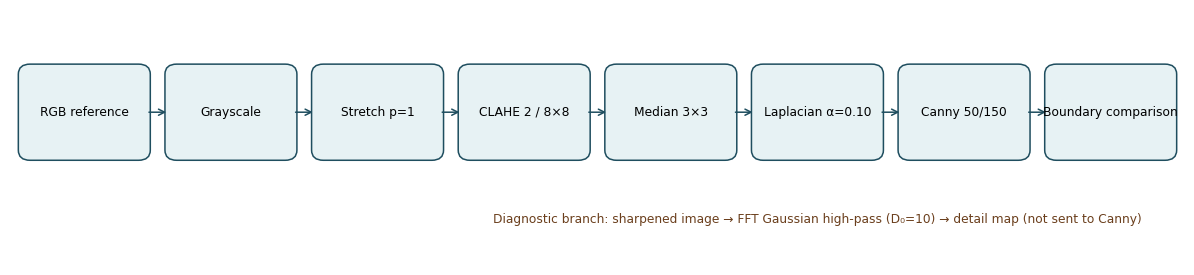

In [ ]:
def draw_pipeline(save_name='02_pipeline_diagram.png'):
    steps = [
        'RGB reference',
        'Grayscale',
        'Stretch p=1',
        'CLAHE 2 / 8×8',
        'Median 3×3',
        'Laplacian α=0.10',
        'Canny 50/150',
        'Boundary comparison',
    ]
    fig, ax = plt.subplots(figsize=(11.2, 2.6))
    ax.set_xlim(0, len(steps))
    ax.set_ylim(0, 2)
    ax.axis('off')
    for i, text in enumerate(steps):
        patch = FancyBboxPatch((i + 0.08, 0.85), 0.84, 0.7,
                                boxstyle='round,pad=0.03,rounding_size=0.08',
                                facecolor='#e7f2f4', edgecolor='#1f4e5f', linewidth=1)
        ax.add_patch(patch)
        ax.text(i + 0.5, 1.2, text, ha='center', va='center', fontsize=8)
        if i < len(steps) - 1:
            ax.annotate('', xy=(i + 1.08, 1.2), xytext=(i + 0.92, 1.2),
                        arrowprops=dict(arrowstyle='->', color='#1f4e5f'))
    ax.text(5.5, 0.35, 'Diagnostic branch: sharpened image → FFT Gaussian high-pass (D₀=10) → detail map (not sent to Canny)',
            ha='center', va='center', fontsize=8, color='#6b3f1d')
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / save_name, bbox_inches='tight')
    plt.show()

draw_pipeline()


## 4. Complete implementation

Each function is the operation used for every image. Helpers do not read files and do not contain a sample index, so the same definitions produce the development comparisons and the test evaluation.


In [ ]:
def stretch(image, p=1):
    """Map intensities between percentiles p and 100-p to 0–255. p=0 is min–max stretch."""
    low, high = np.percentile(image, [p, 100 - p])
    if high <= low:
        return image.copy()
    scaled = (image.astype(np.float32) - low) * 255.0 / (high - low)
    return np.clip(scaled, 0, 255).astype(np.uint8)

def apply_clahe(image, clip=2, grid=8):
    """Local histogram equalization. clip limits amplification; grid is the number of tiles."""
    operator = cv2.createCLAHE(clipLimit=float(clip), tileGridSize=(int(grid), int(grid)))
    return operator.apply(image)

def median_filter(image, k=3):
    """Odd kernel median. k<=1 returns a copy so the bypass is the same type as the filtered result."""
    if int(k) <= 1:
        return image.copy()
    return cv2.medianBlur(image, int(k))

def laplacian_sharpen(image, alpha=0.10):
    """y = clip(x - α ∇²x). Floating-point math avoids uint8 wraparound."""
    values = image.astype(np.float32)
    laplacian = cv2.Laplacian(values, cv2.CV_32F, ksize=3, borderType=cv2.BORDER_REFLECT_101)
    return np.clip(values - alpha * laplacian, 0, 255).astype(np.uint8)

def canny_edges(image, threshold=(50, 150)):
    """Same pre-smoothing and Canny settings for every method under comparison."""
    smoothed = cv2.GaussianBlur(image, (3, 3), 0.8, borderType=cv2.BORDER_REFLECT_101)
    return cv2.Canny(smoothed, int(threshold[0]), int(threshold[1]), apertureSize=3, L2gradient=True)

def fft_highpass(image, d0=10, pad=32):
    """Gaussian high-pass H = 1 - exp(-D² / (2 D0²)). Reflect padding limits wraparound."""
    padded = np.pad(image.astype(np.float32), pad, mode='reflect')
    height, width = padded.shape
    yy, xx = np.ogrid[:height, :width]
    distance_sq = (yy - height // 2) ** 2 + (xx - width // 2) ** 2
    transfer = 1.0 - np.exp(-distance_sq / (2.0 * d0 * d0))
    spectrum = np.fft.fftshift(np.fft.fft2(padded)) * transfer
    restored = np.fft.ifft2(np.fft.ifftshift(spectrum)).real
    return restored[pad:-pad, pad:-pad]

def enhance(image, p=1, clip=2, grid=8, k=3, alpha=0.10):
    """Serial path through the sharpened grayscale image. Canny is applied by the caller."""
    stretched = stretch(image, p)
    equalized = apply_clahe(stretched, clip, grid)
    smoothed = median_filter(equalized, k)
    sharpened = laplacian_sharpen(smoothed, alpha)
    return {
        'stretch': stretched,
        'clahe': equalized,
        'median': smoothed,
        'sharpened': sharpened,
    }

def line_stats(edge, min_len=16):
    """Long-line structure of a Canny map.

    length: total length of Hough segments at least min_len pixels long.
    ortho: length of those segments within 12 degrees of the dominant orientation or of that orientation plus 90 degrees.
    support: fraction of edge pixels that lie on a 1-pixel dilation of the long segments.
    density: percent of pixels that are edge pixels.
    """
    lines = cv2.HoughLinesP(
        edge, 1, np.pi / 180, threshold=15, minLineLength=min_len, maxLineGap=2
    )
    density = float((edge > 0).mean() * 100)
    if lines is None:
        return 0.0, 0.0, 0.0, density
    segments = lines[:, 0].astype(float)
    lengths = np.hypot(segments[:, 2] - segments[:, 0], segments[:, 3] - segments[:, 1])
    angles = np.arctan2(segments[:, 3] - segments[:, 1], segments[:, 2] - segments[:, 0]) % np.pi
    bins = np.linspace(0, np.pi, 18, endpoint=False)
    bin_index = np.digitize(angles, bins) - 1
    histogram = np.bincount(bin_index, weights=lengths, minlength=len(bins))
    mode = bins[int(np.argmax(histogram))] + (np.pi / len(bins) / 2)

    def angular_distance(a, b):
        delta = np.abs(a - b) % np.pi
        return np.minimum(delta, np.pi - delta)

    aligned = np.minimum(
        angular_distance(angles, mode),
        angular_distance(angles, mode + np.pi / 2),
    ) <= np.deg2rad(12)
    mask = np.zeros(edge.shape, np.uint8)
    for x1, y1, x2, y2 in segments.astype(int):
        cv2.line(mask, (int(x1), int(y1)), (int(x2), int(y2)), 255, 1)
    dilated = cv2.dilate(mask, np.ones((3, 3), np.uint8))
    edge_pixels = edge > 0
    support = float((edge_pixels & (dilated > 0)).sum() / max(int(edge_pixels.sum()), 1))
    return float(lengths.sum()), float(lengths[aligned].sum()), support, density

def quality(image, threshold=(50, 150)):
    """Contrast, gradient, clipping, and structural-line measures for one grayscale image."""
    values = image.astype(np.float32)
    gx = cv2.Sobel(values, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(values, cv2.CV_32F, 0, 1, ksize=3)
    length, ortho, support, density = line_stats(canny_edges(image, threshold))
    return {
        'sd': float(image.std()),
        'sobel': float(np.hypot(gx, gy).mean()),
        'sat': float(((image == 0) | (image == 255)).mean() * 100),
        'length': length,
        'ortho': ortho,
        'support': support,
        'density': density,
    }

def mean_quality(images, threshold=(50, 150)):
    rows = [quality(image, threshold) for image in images]
    return {key: float(np.mean([row[key] for row in rows])) for key in rows[0]}

def print_metrics(title, metrics):
    print(
        f"{title:22}  SD={metrics['sd']:7.3f}  Sobel={metrics['sobel']:7.3f}  "
        f"Sat={metrics['sat']:6.3f}%  Edge={metrics['density']:6.3f}%  "
        f"Lines={metrics['length']:7.3f}  Ortho={metrics['ortho']:7.3f}  "
        f"Support={metrics['support']:.3f}"
    )


## 5. Experimental results and parameter comparison

All numbers in this section are means over the **40 development images** (20 damage and 20 no_damage). One control is changed at a time. The other controls stay at the frozen pipeline: stretch p = 1, CLAHE clip 2 and 8×8 tiles, median k = 3, Laplacian α = 0.10, Canny (50, 150). The reported row is the **output of the full serial path** under that setting, so the comparison includes how the choice changes later boundary detection. The test set is not in these tables.

**How to read the columns.** Contrast SD and Sobel magnitude describe the enhanced image. Saturation is the percent of pixels at 0 or 255; clipping throws away roof highlights. Edge percent is Canny density and is not a quality score by itself. Lines is the total length of Hough segments of at least 16 pixels. Ortho is the part of that length aligned with the dominant direction or with the direction 90 degrees from it. Building edges tend to be long and mutually parallel or perpendicular. Vegetation speckle does not. Support is the fraction of Canny pixels that lie on those long segments.


In [ ]:
dev_gray = [item['gray'] for item in development]

def full_output(image, p=1, clip=2, grid=8, k=3, alpha=0.10):
    return enhance(image, p=p, clip=clip, grid=grid, k=k, alpha=alpha)['sharpened']

experiments = [
    ('Stretch percentile', [dict(p=value) for value in (0, 1, 2)]),
    ('CLAHE clip', [dict(clip=value) for value in (1, 2, 4)]),
    ('CLAHE grid', [dict(grid=value) for value in (4, 8)]),
    ('Median kernel', [dict(k=value) for value in (1, 3, 5)]),
    ('Laplacian alpha', [dict(alpha=value) for value in (0.10, 0.25, 0.50)]),
]
development_tables = {}
for experiment_name, variants in experiments:
    print('\n' + experiment_name)
    rows = []
    for variant in variants:
        settings = dict(p=1, clip=2, grid=8, k=3, alpha=0.10)
        settings.update(variant)
        metrics = mean_quality([full_output(image, **settings) for image in dev_gray])
        label = ', '.join(f'{key}={value}' for key, value in variant.items())
        print_metrics(label, metrics)
        rows.append((label, metrics))
    development_tables[experiment_name] = rows

print('\nCanny thresholds on the frozen enhanced image')
canny_rows = []
for threshold in ((30, 90), (50, 150), (80, 200)):
    metrics = mean_quality([full_output(image) for image in dev_gray], threshold=threshold)
    label = f'{threshold[0]}/{threshold[1]}'
    print_metrics(label, metrics)
    canny_rows.append((label, metrics))
development_tables['Canny'] = canny_rows



Stretch percentile
p=0                     SD= 50.851  Sobel=116.246  Sat= 0.518%  Edge=18.622%  Lines=202.768  Ortho=138.544  Support=0.087
p=1                     SD= 64.145  Sobel=137.417  Sat= 2.968%  Edge=20.331%  Lines=233.969  Ortho=148.867  Support=0.093
p=2                     SD= 68.514  Sobel=142.676  Sat= 4.768%  Edge=20.550%  Lines=246.655  Ortho=154.563  Support=0.097

CLAHE clip
clip=1                  SD= 64.106  Sobel=122.972  Sat= 3.420%  Edge=18.176%  Lines=214.911  Ortho=138.284  Support=0.095
clip=2                  SD= 64.145  Sobel=137.417  Sat= 2.968%  Edge=20.331%  Lines=233.969  Ortho=148.867  Support=0.093
clip=4                  SD= 62.802  Sobel=156.813  Sat= 2.772%  Edge=22.993%  Lines=267.275  Ortho=163.039  Support=0.095

CLAHE grid
grid=4                  SD= 61.201  Sobel=122.477  Sat= 2.527%  Edge=18.652%  Lines=211.101  Ortho=152.038  Support=0.090
grid=8                  SD= 64.145  Sobel=137.417  Sat= 2.968%  Edge=20.331%  Lines=233.969  Ortho=148

damage train_another/damage/-95.643284_29.862091999999997.jpeg


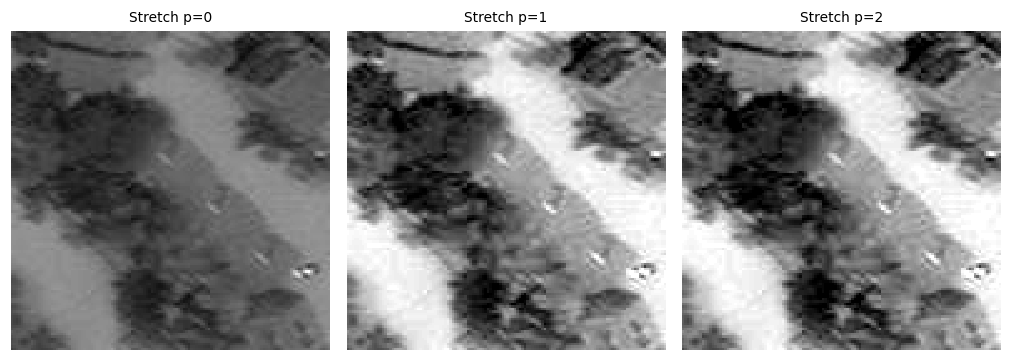

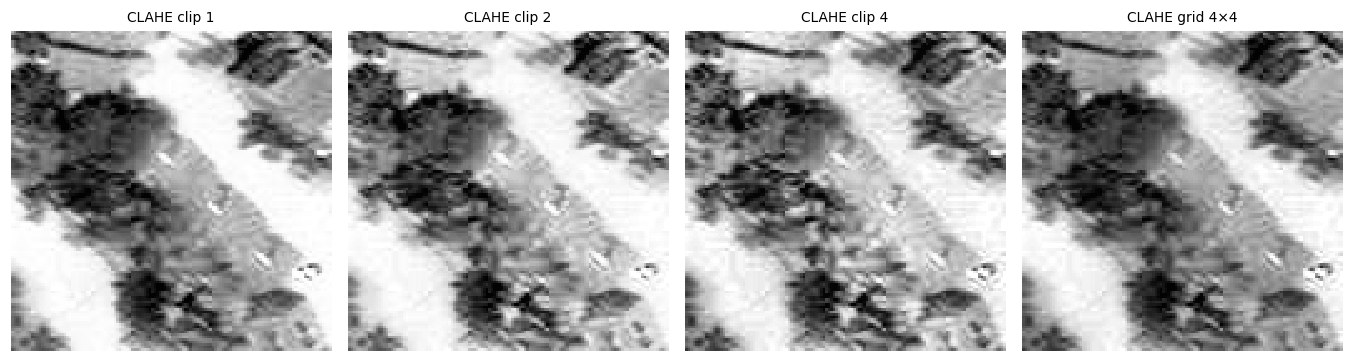

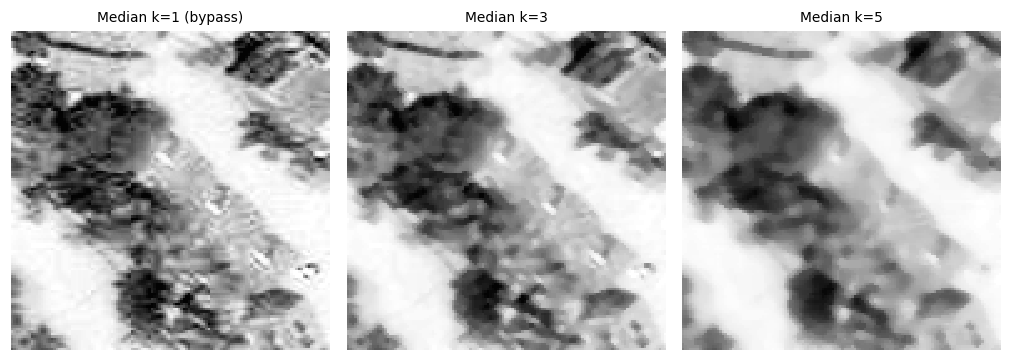

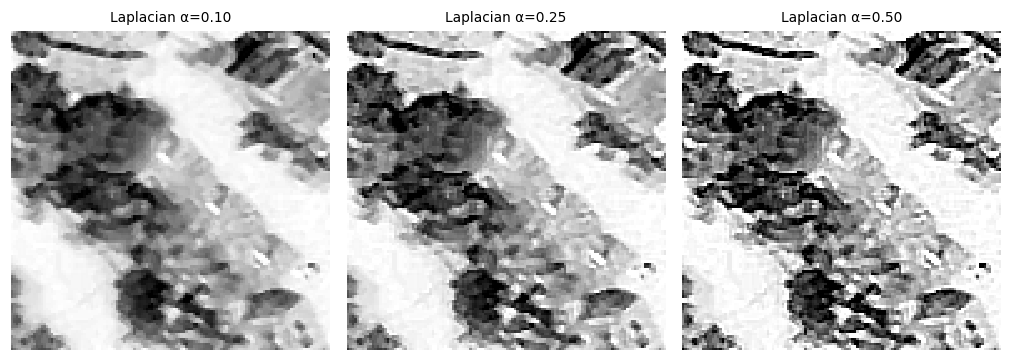

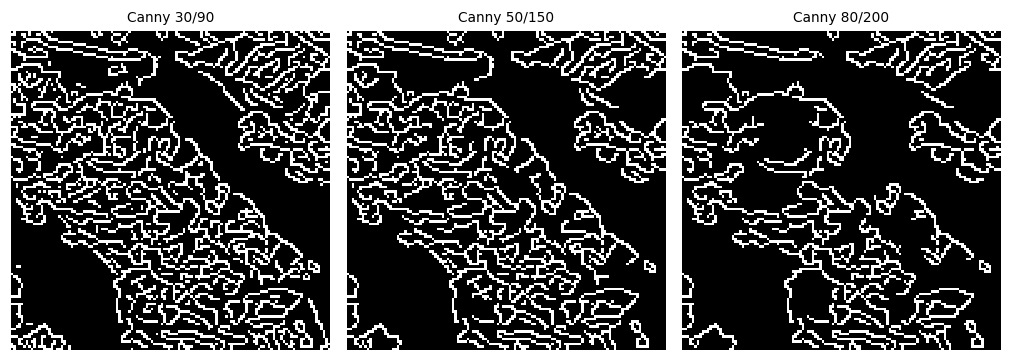

no_damage validation_another/no_damage/-95.63141800000001_29.843921.jpeg


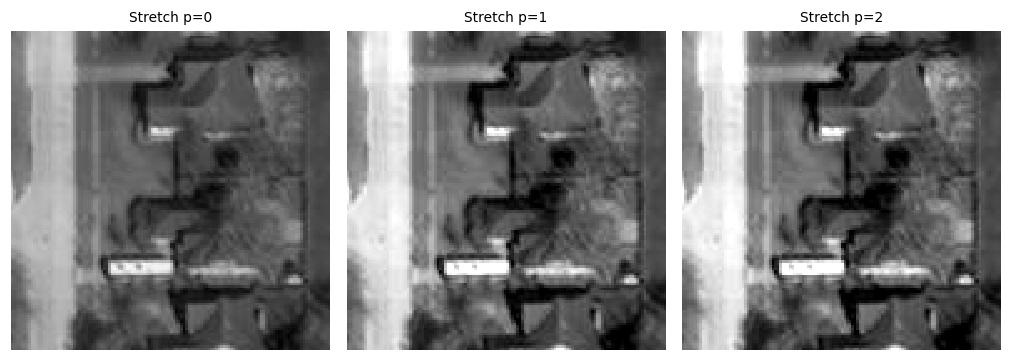

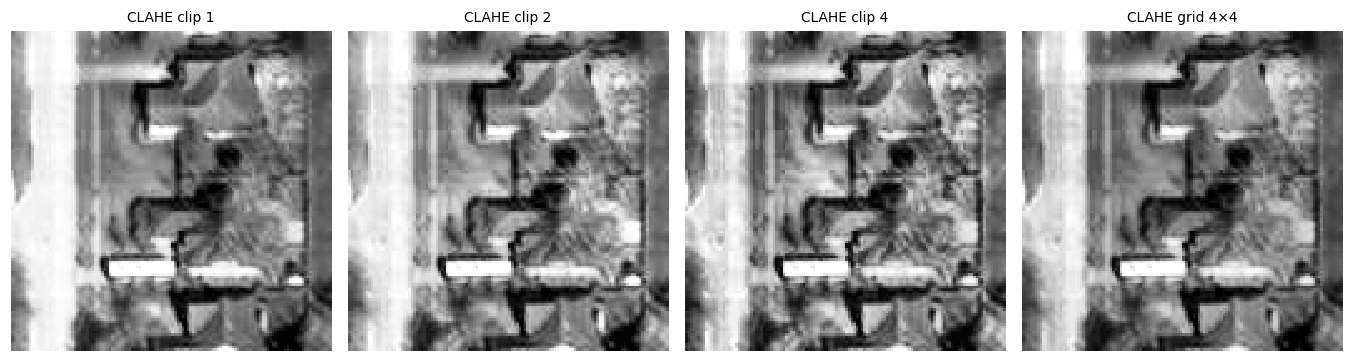

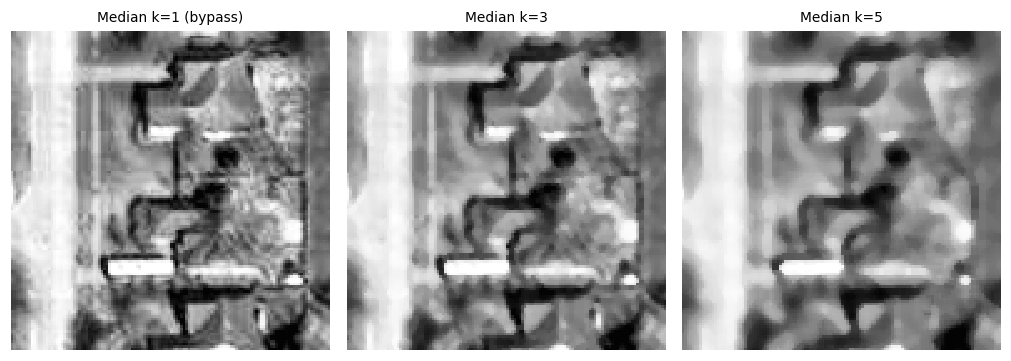

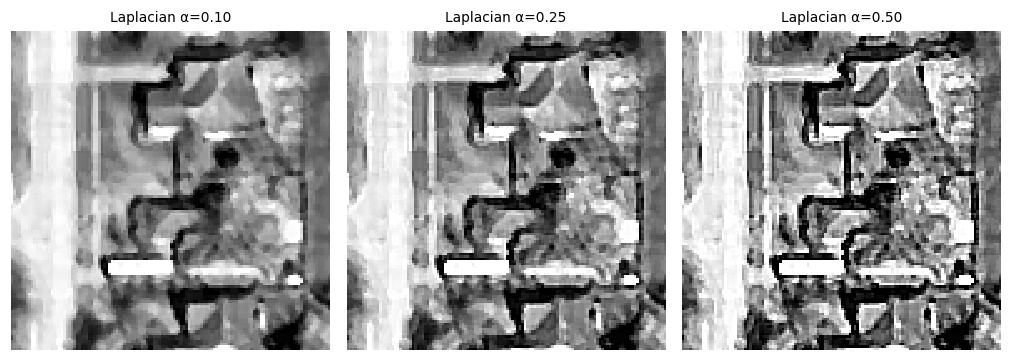

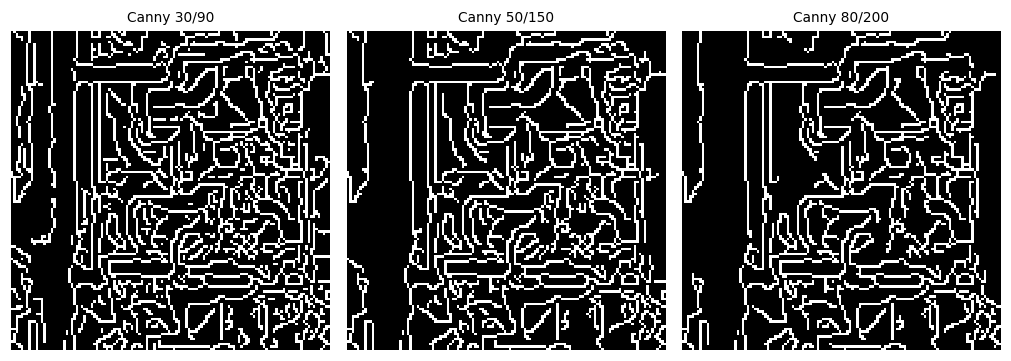

In [ ]:
# Visual parameter comparison on one development image from each class.
# Numbers above are the 40-image means; these two patches show the same settings.
visual_dev = [development[0], next(item for item in development if item['label'] == 'no_damage')]

def panel_for(image, variants, titles, builder):
    show_row([builder(image, **variant) for variant in variants], titles)

for item in visual_dev:
    gray = item['gray']
    print(item['label'], item['rel'])
    panel_for(
        gray,
        [dict(p=0), dict(p=1), dict(p=2)],
        ['Stretch p=0', 'Stretch p=1', 'Stretch p=2'],
        lambda image, p: stretch(image, p),
    )
    base = stretch(gray, 1)
    panel_for(
        base,
        [dict(clip=1), dict(clip=2), dict(clip=4), dict(grid=4)],
        ['CLAHE clip 1', 'CLAHE clip 2', 'CLAHE clip 4', 'CLAHE grid 4×4'],
        lambda image, clip=2, grid=8: apply_clahe(image, clip, grid),
    )
    equalized = apply_clahe(base, 2, 8)
    panel_for(
        equalized,
        [dict(k=1), dict(k=3), dict(k=5)],
        ['Median k=1 (bypass)', 'Median k=3', 'Median k=5'],
        lambda image, k: median_filter(image, k),
    )
    smoothed = median_filter(equalized, 3)
    panel_for(
        smoothed,
        [dict(alpha=0.10), dict(alpha=0.25), dict(alpha=0.50)],
        ['Laplacian α=0.10', 'Laplacian α=0.25', 'Laplacian α=0.50'],
        lambda image, alpha: laplacian_sharpen(image, alpha),
    )
    final = laplacian_sharpen(smoothed, 0.10)
    show_row(
        [canny_edges(final, threshold) for threshold in ((30, 90), (50, 150), (80, 200))],
        ['Canny 30/90', 'Canny 50/150', 'Canny 80/200'],
    )


damage signed high-pass RMS before display scaling


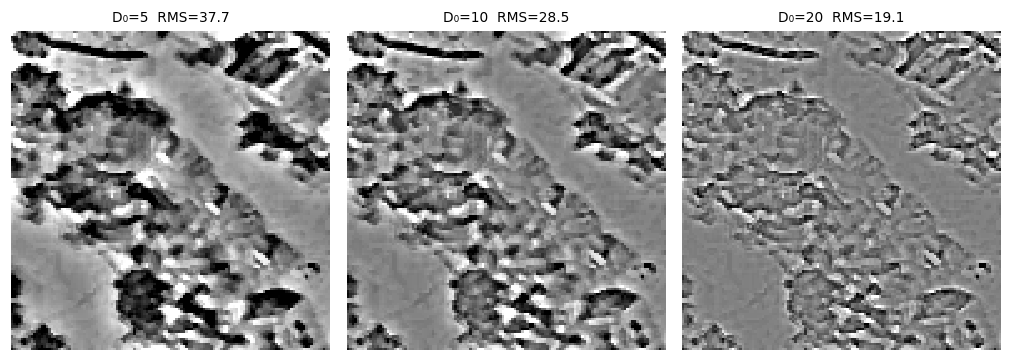

no_damage signed high-pass RMS before display scaling


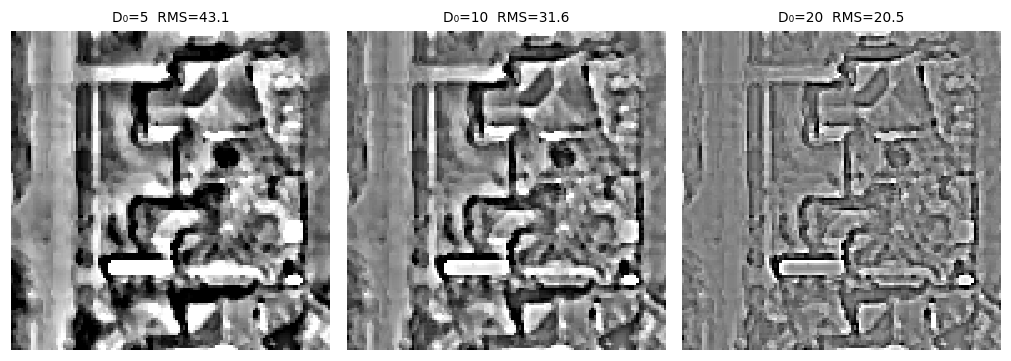

In [ ]:
# Frequency branch on the same two development images. Display gain is fixed and is not used later.
for item in visual_dev:
    sharpened = full_output(item['gray'])
    maps = []
    titles = []
    for cutoff in (5, 10, 20):
        response = fft_highpass(sharpened, cutoff)
        shown = np.clip(128 + 2 * response, 0, 255).astype(np.uint8)
        maps.append(shown)
        titles.append(f'D₀={cutoff}  RMS={np.sqrt(np.mean(response ** 2)):.1f}')
    print(item['label'], 'signed high-pass RMS before display scaling')
    show_row(maps, titles)


### Parameter decisions

The choices below were locked from the development tables before the test metrics were interpreted.

**Stretch p = 1.** On the 40 development images, p = 1 reaches orthogonal length 148.867 with 2.968% saturated pixels. p = 0 saturates only 0.518% but orthogonal length stays lower, at 138.544. p = 2 reaches 154.563 and saturates 4.768%. The extra line length at p = 2 is small next to the extra clipping of bright roofs, so p = 1 remains the operating point.

**CLAHE clip = 2 and grid = 8×8.** Clip 4 raises orthogonal length from 148.867 to 163.039, but edge density rises from 20.331% to 22.993% while the support fraction stays near 0.095. The added response is not a cleaner set of building lines. Clip 1 is milder (orthogonal length 138.284) and loses structure that clip 2 keeps. Grid 4×4 has a slightly higher orthogonal score (152.038 versus 148.867) but a shorter total long-line length (211.101 versus 233.969). The 8×8 grid is kept because it preserves more extended structure at a similar alignment rate.

**Median k = 3.** Bypassing the median (k = 1) produces orthogonal length 226.419, saturation 5.852%, and edge density 25.281%. A 5×5 kernel drops orthogonal length to 98.993, which removes building-scale lines rather than only speckle. The 3×3 kernel sits between them: orthogonal length 148.867, saturation 2.968%, edge density 20.331%. It is a clutter control, not a claim that the sensor has salt-and-pepper noise.

**Laplacian α = 0.10.** α = 0.25 raises orthogonal length to 188.290 and saturation to 7.190%. α = 0.50 reaches saturation 14.504%. The stronger weights create bright halos and clipped outlines. Those extra lines are not accepted as better building boundaries.

**Canny (50, 150).** Thresholds 30/90 produce orthogonal length 184.787 and edge density 24.275%. Thresholds 80/200 stay close on aligned length (143.638 versus 148.867) with lower density (16.247%). The support fractions are similar across the three pairs. The middle pair is kept because it retains more extended structure than 80/200 without the weak texture admitted by 30/90.

**FFT cutoff D₀ = 10, diagnostic only.** The displayed maps are centered at gray 128 with a fixed gain of 2. A larger cutoff removes more mid-frequency content, so RMS falls from D₀ = 5 to D₀ = 20. The branch shows detail. It does not replace the grayscale image that enters Canny.

## 6. Final results and evaluation

The frozen pipeline is applied to the **40 test images**. No threshold, clip, kernel, or percentile in this section was chosen from these images.

**Stage ablation.** Each row is that stage’s own output, not the final image. This shows what each stage contributes. `No median` is the frozen pipeline with the median removed, included so the bypass can be judged on the test set after the development choice was locked.

**Structural reading.** Orthogonal line length is the main full-set measure of building-like boundaries. Edge density is reported beside it so a gain that is only speckle is visible. Support falling while density rises means a smaller share of the new edges lie on long lines.

**Traced boundaries.** On 8 of the 40 test images, roof edges, road edges, and other straight structural boundaries that are identifiable in the color patch were traced by hand. A percentile-stretched view was used only as a drawing aid. Ambiguous vegetation was left untraced, so the reference is partial. A detection counts as a match within 2 pixels. Recall is the fraction of traced boundary pixels recovered. Precision is the fraction of Canny pixels that land near a traced boundary. Because untraced true boundaries count against precision, precision is conservative. Recall is the direct answer to whether the traced boundaries were found. This is not an official footprint dataset, and the 8-image subset is too small to stand alone. It is interpreted together with the 40-image line measures.


In [ ]:
test_gray = [item['gray'] for item in heldout]

def stage_bank(image):
    parts = enhance(image)
    parts['original'] = image
    parts['no_median'] = laplacian_sharpen(parts['clahe'], 0.10)
    return parts

stage_order = [
    ('Original', 'original'),
    ('Stretch', 'stretch'),
    ('CLAHE', 'clahe'),
    ('Median', 'median'),
    ('Full pipeline', 'sharpened'),
    ('Full, no median', 'no_median'),
]
print('Independent test set: 40 images (20 damage, 20 no_damage)')
print('Stage metrics are means. Full pipeline is the frozen serial path.')
test_stage_metrics = {}
for title, key in stage_order:
    metrics = mean_quality([stage_bank(image)[key] for image in test_gray])
    test_stage_metrics[title] = metrics
    print_metrics(title, metrics)

print('\nBy class, original versus full pipeline (20 images each)')
for label in ('damage', 'no_damage'):
    group = [item['gray'] for item in heldout if item['label'] == label]
    print_metrics(f'{label} original', mean_quality(group))
    print_metrics(f'{label} full', mean_quality([full_output(image) for image in group]))


Independent test set: 40 images (20 damage, 20 no_damage)
Stage metrics are means. Full pipeline is the frozen serial path.
Original                SD= 29.310  Sobel= 44.931  Sat= 0.009%  Edge= 4.577%  Lines= 86.617  Ortho= 73.455  Support=0.157
Stretch                 SD= 53.785  Sobel= 86.274  Sat= 2.193%  Edge=11.112%  Lines=150.671  Ortho=108.064  Support=0.124
CLAHE                   SD= 58.129  Sobel=124.747  Sat= 1.132%  Edge=17.560%  Lines=229.544  Ortho=141.522  Support=0.111
Median                  SD= 56.393  Sobel= 99.906  Sat= 0.882%  Edge=13.299%  Lines=142.801  Ortho=104.297  Support=0.097
Full pipeline           SD= 59.373  Sobel=122.370  Sat= 2.569%  Edge=17.155%  Lines=210.640  Ortho=135.917  Support=0.107
Full, no median         SD= 62.677  Sobel=166.397  Sat= 5.172%  Edge=22.680%  Lines=405.899  Ortho=216.713  Support=0.142

By class, original versus full pipeline (20 images each)
damage original         SD= 26.629  Sobel= 38.243  Sat= 0.019%  Edge= 2.812%  Lines= 3

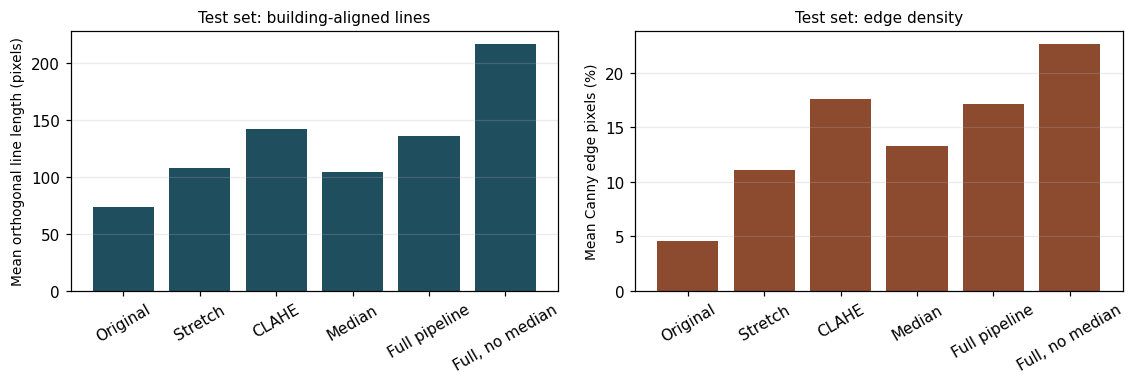

In [ ]:
labels = list(test_stage_metrics)
ortho_values = [test_stage_metrics[name]['ortho'] for name in labels]
density_values = [test_stage_metrics[name]['density'] for name in labels]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
axes[0].bar(labels, ortho_values, color='#1f4e5f')
axes[0].set_ylabel('Mean orthogonal line length (pixels)')
axes[0].set_title('Test set: building-aligned lines')
axes[1].bar(labels, density_values, color='#8c4a2f')
axes[1].set_ylabel('Mean Canny edge pixels (%)')
axes[1].set_title('Test set: edge density')
for ax in axes:
    ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / '03_test_stage_comparison.png', bbox_inches='tight')
plt.show()


damage test/damage/-95.24073800000001_29.562787.jpeg


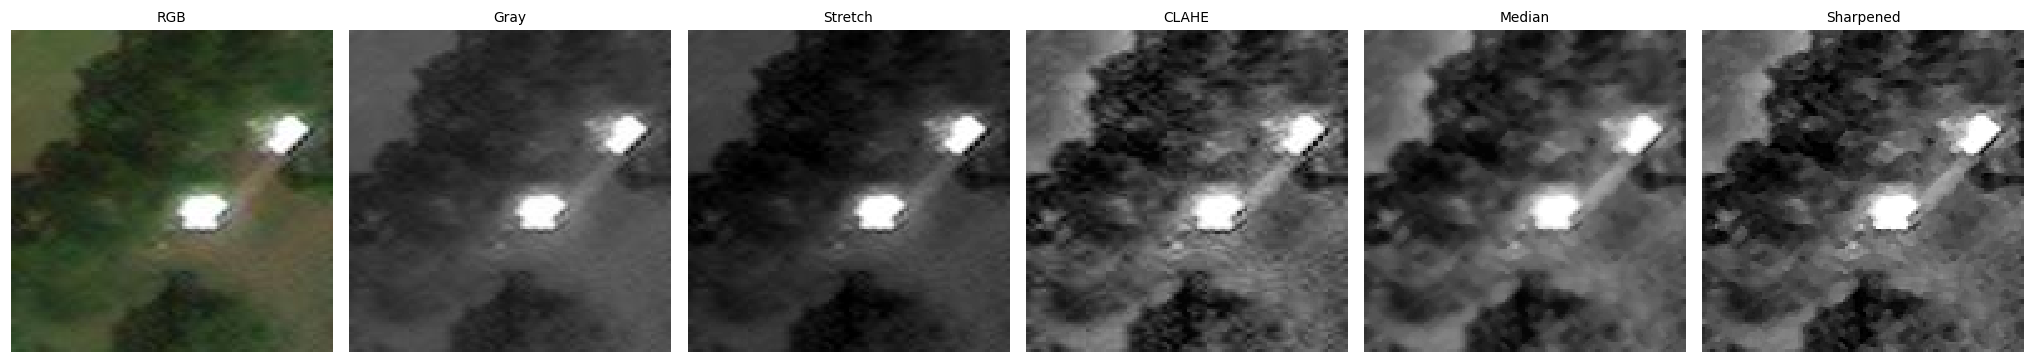

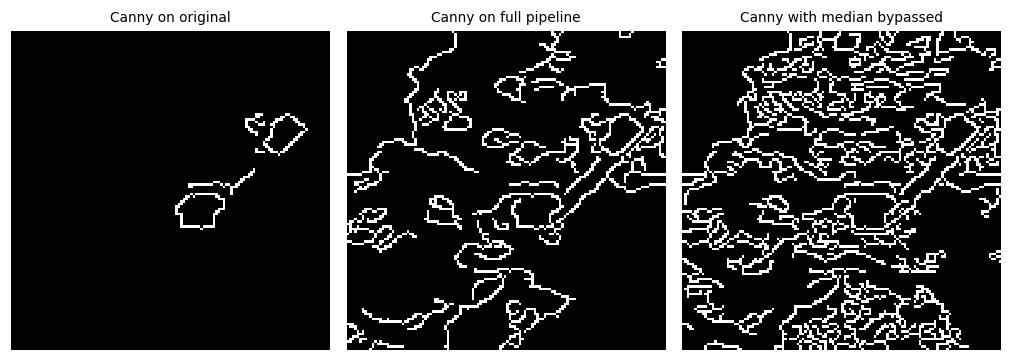

no_damage train_another/no_damage/-95.15769499999999_29.755406.jpeg


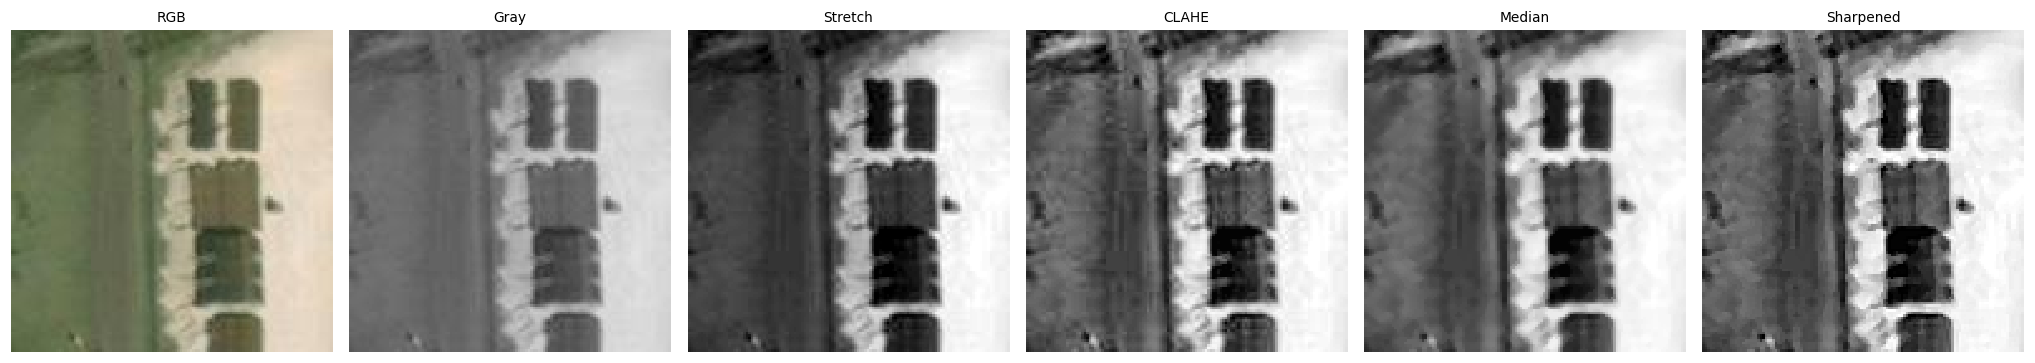

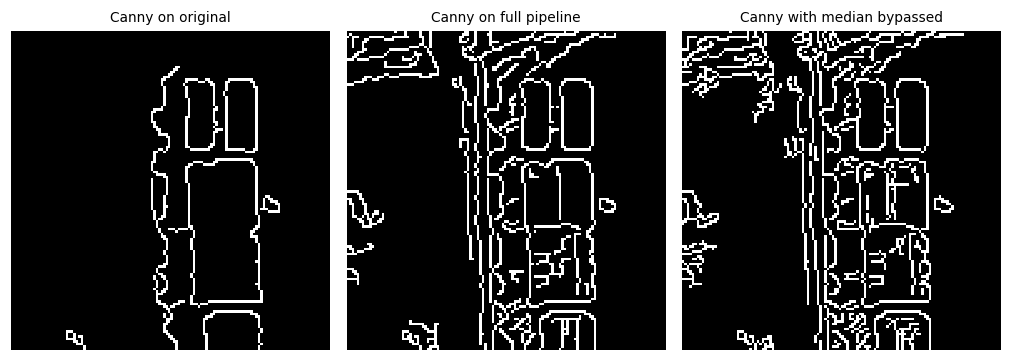

In [ ]:
# Walk two test images through every serial stage, plus Canny before and after enhancement.
for item in (annotated[0], annotated[7]):
    bank = stage_bank(item['gray'])
    print(item['label'], item['rel'])
    show_row(
        [item['rgb'], bank['original'], bank['stretch'], bank['clahe'], bank['median'], bank['sharpened']],
        ['RGB', 'Gray', 'Stretch', 'CLAHE', 'Median', 'Sharpened'],
    )
    show_row(
        [canny_edges(bank['original']), canny_edges(bank['sharpened']), canny_edges(bank['no_median'])],
        ['Canny on original', 'Canny on full pipeline', 'Canny with median bypassed'],
    )


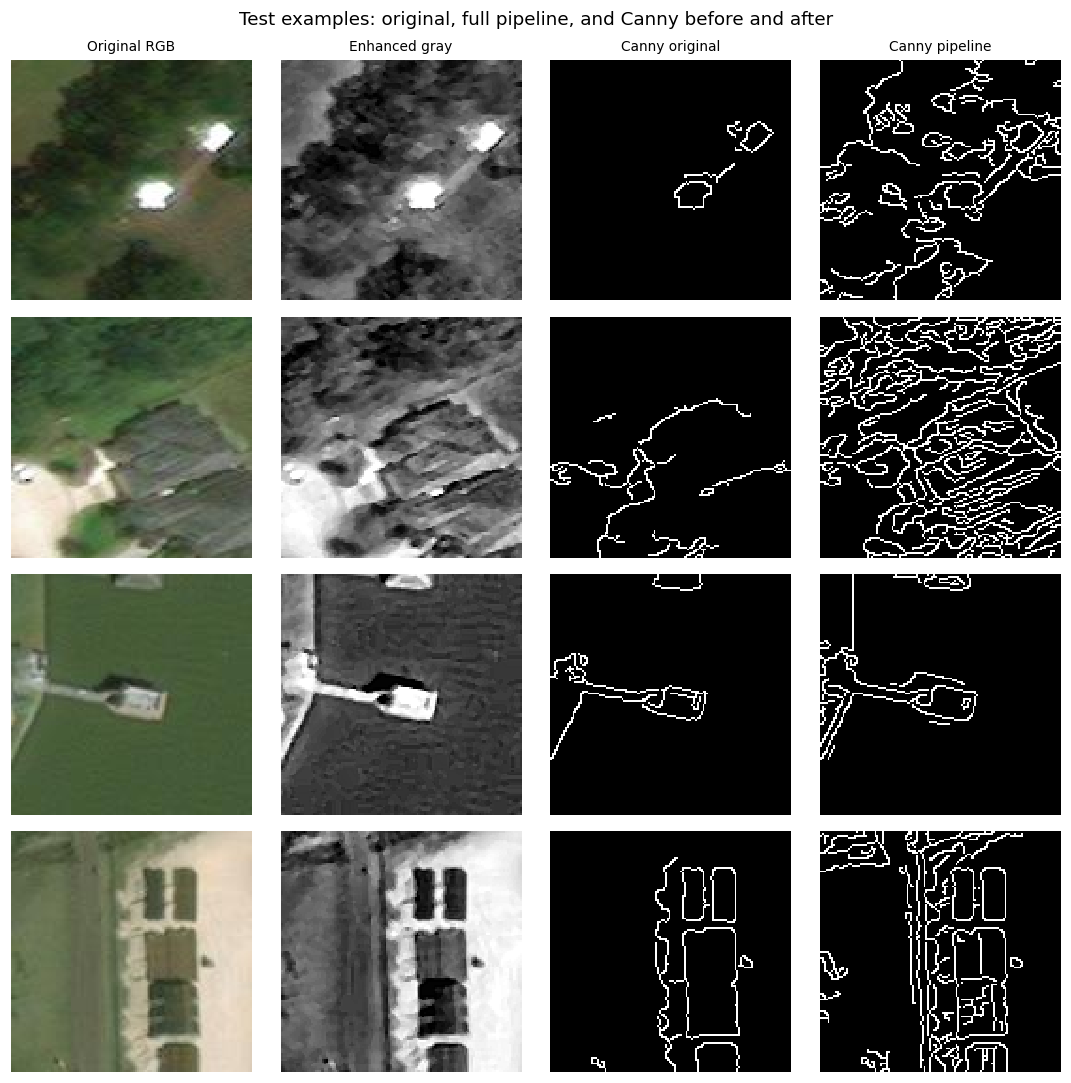

In [ ]:
# Four test images: original, enhanced, and the two edge maps.
quad = [annotated[0], annotated[1], annotated[4], annotated[7]]
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
column_titles = ['Original RGB', 'Enhanced gray', 'Canny original', 'Canny pipeline']
for row, item in enumerate(quad):
    sharpened = full_output(item['gray'])
    views = [item['rgb'], sharpened, canny_edges(item['gray']), canny_edges(sharpened)]
    for col, view in enumerate(views):
        ax = axes[row, col]
        if view.ndim == 2:
            ax.imshow(view, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
        else:
            ax.imshow(view, interpolation='nearest')
        ax.axis('off')
        if row == 0:
            ax.set_title(column_titles[col], fontsize=9)
        if col == 0:
            ax.set_ylabel(item['label'], fontsize=8)
fig.suptitle('Test examples: original, full pipeline, and Canny before and after', fontsize=12)
fig.tight_layout()
fig.savefig(FIGURE_DIR / '04_test_before_after.png', bbox_inches='tight')
plt.show()


In [ ]:
# Author-traced structural boundaries for the 8 test images, in original pixel coordinates.
# Each entry is a list of ((x1, y1), (x2, y2)) segments.
REFERENCE_LINES = {
    'test/damage/-95.24073800000001_29.562787.jpeg': [
        ((89, 33), (110, 35)), ((102, 28), (122, 30)), ((92, 69), (108, 52)),
        ((87, 64), (102, 50)), ((110, 64), (126, 61)),
    ],
    'test_another/damage/-95.133131_30.047952000000002.jpeg': [
        ((62, 57), (88, 47)), ((82, 68), (102, 73)), ((88, 83), (103, 76)),
        ((97, 89), (112, 83)), ((71, 34), (88, 33)), ((69, 45), (85, 39)),
    ],
    'test_another/damage/-95.137884_29.987885.jpeg': [
        ((56, 83), (69, 58)), ((66, 78), (73, 61)), ((90, 64), (96, 45)),
        ((96, 65), (102, 48)), ((75, 97), (93, 92)),
    ],
    'test_another/damage/-95.140961_29.996931.jpeg': [
        ((40, 42), (71, 34)), ((36, 48), (59, 45)), ((46, 37), (64, 31)),
        ((77, 115), (99, 108)), ((29, 101), (49, 102)),
    ],
    'train_another/no_damage/-95.15228499999999_30.028059999999996.jpeg': [
        ((17, 1), (17, 63)), ((0, 99), (17, 63)), ((21, 58), (48, 63)),
        ((18, 66), (48, 68)), ((52, 51), (76, 57)), ((54, 73), (78, 77)), ((56, 7), (78, 8)),
    ],
    'train_another/no_damage/-95.152913_30.019790000000004.jpeg': [
        ((38, 68), (66, 52)), ((76, 18), (104, 8)), ((79, 98), (102, 81)),
        ((7, 109), (34, 108)), ((32, 20), (52, 29)), ((38, 15), (56, 23)), ((97, 33), (107, 13)),
    ],
    'train_another/no_damage/-95.156802_30.021576.jpeg': [
        ((86, 60), (104, 61)), ((55, 37), (63, 56)), ((56, 53), (62, 72)),
    ],
    'train_another/no_damage/-95.15769499999999_29.755406.jpeg': [
        ((52, 13), (54, 119)), ((98, 23), (98, 48)), ((67, 109), (98, 107)),
        ((74, 114), (93, 111)), ((70, 56), (71, 77)),
    ],
}

def raster_reference(segments, shape=(128, 128)):
    mask = np.zeros(shape, np.uint8)
    for (x1, y1), (x2, y2) in segments:
        cv2.line(mask, (int(x1), int(y1)), (int(x2), int(y2)), 255, 1)
    return mask

def boundary_scores(detected, reference, tolerance=2):
    kernel = np.ones((2 * tolerance + 1, 2 * tolerance + 1), np.uint8)
    ref_on = reference > 0
    det_on = detected > 0
    recall = float((ref_on & (cv2.dilate(detected, kernel) > 0)).sum() / max(int(ref_on.sum()), 1))
    precision = float((det_on & (cv2.dilate(reference, kernel) > 0)).sum() / max(int(det_on.sum()), 1))
    f1 = 0.0 if precision + recall == 0 else 2 * precision * recall / (precision + recall)
    return precision, recall, f1

assert set(REFERENCE_LINES) == {item['rel'] for item in annotated}

methods = stage_order
per_image = {title: [] for title, _ in methods}
print('Traced-boundary scores on 8 test images, tolerance = 2 pixels')
print(f"{'image':52} " + ' '.join(f'{title[:8]:>8}' for title, _ in methods))
for item in annotated:
    bank = stage_bank(item['gray'])
    reference = raster_reference(REFERENCE_LINES[item['rel']])
    recalls = []
    for title, key in methods:
        precision, recall, f1 = boundary_scores(canny_edges(bank[key]), reference)
        per_image[title].append((precision, recall, f1))
        recalls.append(f'{recall:8.3f}')
    print(f"{item['rel'][-52:]:52} " + ' '.join(recalls))

print('\nMeans over the 8 annotated test images')
annotation_means = {}
for title, _ in methods:
    array = np.array(per_image[title])
    annotation_means[title] = {
        'precision': float(array[:, 0].mean()),
        'recall': float(array[:, 1].mean()),
        'f1': float(array[:, 2].mean()),
    }
    stats = annotation_means[title]
    print(f"{title:22}  P={stats['precision']:.3f}  R={stats['recall']:.3f}  F1={stats['f1']:.3f}")


Traced-boundary scores on 8 test images, tolerance = 2 pixels
image                                                Original  Stretch    CLAHE   Median Full pip Full, no
test/damage/-95.24073800000001_29.562787.jpeg           0.351    0.628    0.968    0.830    0.968    1.000
st_another/damage/-95.133131_30.047952000000002.jpeg    0.130    0.183    1.000    1.000    1.000    1.000
test_another/damage/-95.137884_29.987885.jpeg           0.436    1.000    1.000    0.990    1.000    1.000
test_another/damage/-95.140961_29.996931.jpeg           0.765    0.975    1.000    0.992    1.000    1.000
no_damage/-95.15228499999999_30.028059999999996.jpeg    0.697    0.974    0.996    0.991    0.996    0.987
another/no_damage/-95.152913_30.019790000000004.jpeg    0.930    0.971    1.000    0.982    1.000    1.000
train_another/no_damage/-95.156802_30.021576.jpeg       0.695    0.966    0.966    0.932    1.000    1.000
_another/no_damage/-95.15769499999999_29.755406.jpeg    0.478    0.483    1.000   

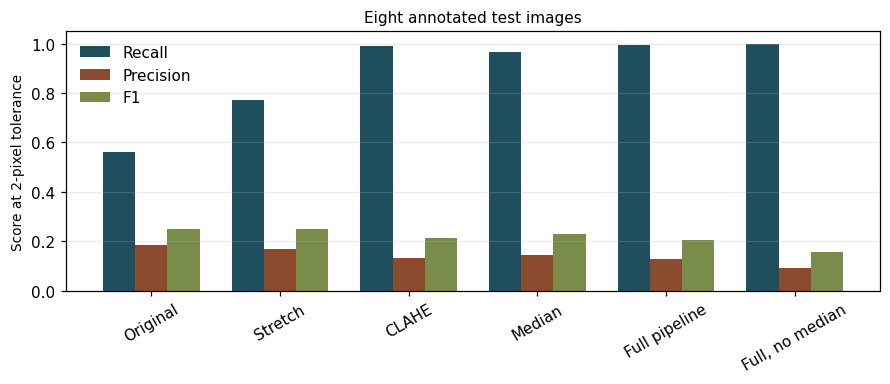

damage test/damage/-95.24073800000001_29.562787.jpeg


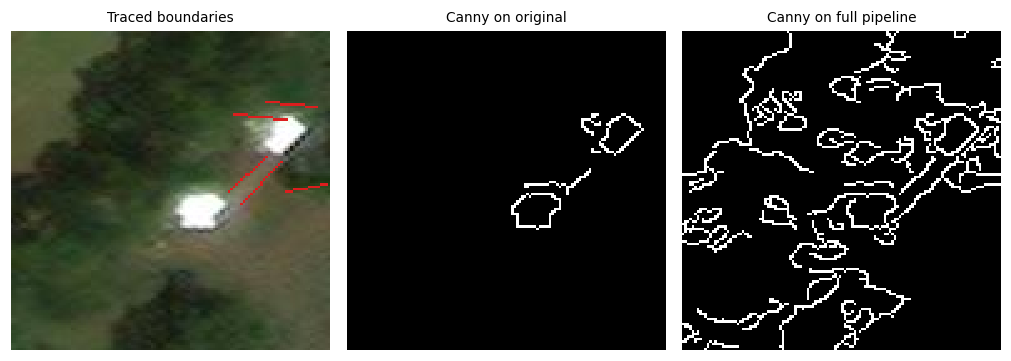

no_damage train_another/no_damage/-95.15228499999999_30.028059999999996.jpeg


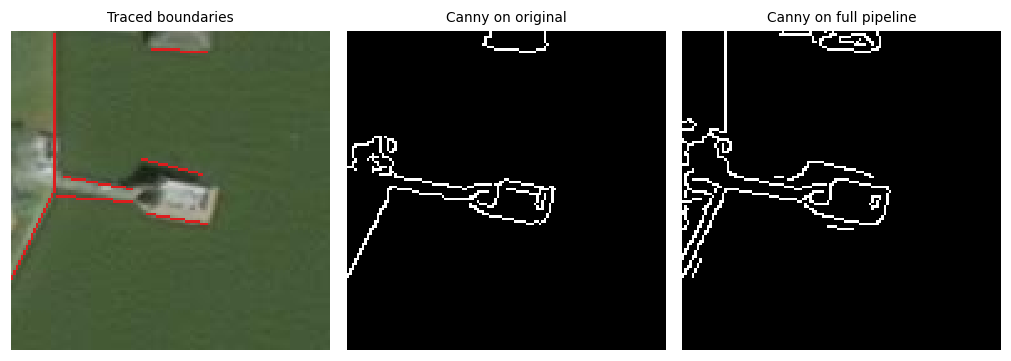

no_damage train_another/no_damage/-95.152913_30.019790000000004.jpeg


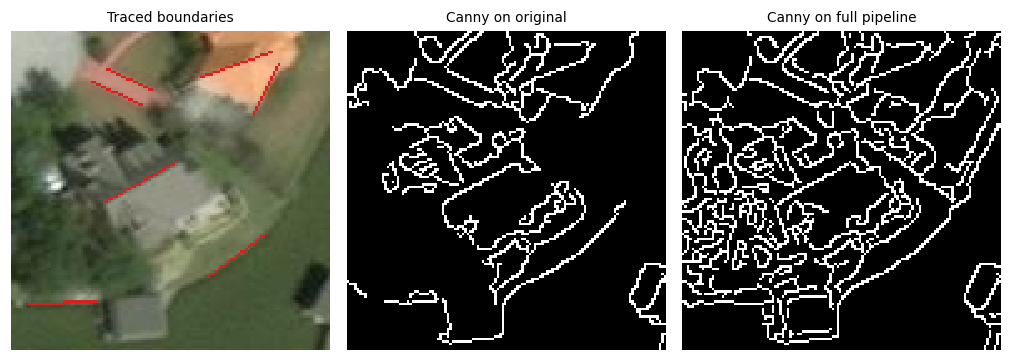

no_damage train_another/no_damage/-95.15769499999999_29.755406.jpeg


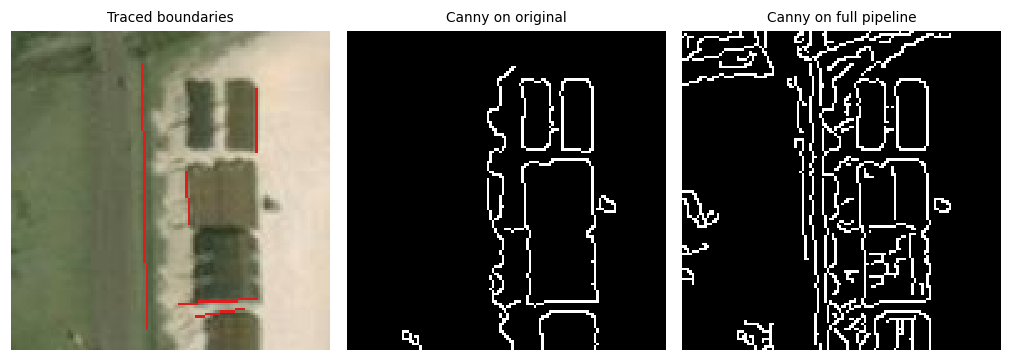

In [ ]:
fig, ax = plt.subplots(figsize=(8.2, 3.6))
names = list(annotation_means)
x = np.arange(len(names))
width = 0.25
ax.bar(x - width, [annotation_means[n]['recall'] for n in names], width, label='Recall', color='#1f4e5f')
ax.bar(x, [annotation_means[n]['precision'] for n in names], width, label='Precision', color='#8c4a2f')
ax.bar(x + width, [annotation_means[n]['f1'] for n in names], width, label='F1', color='#7a8c4a')
ax.set_xticks(x)
ax.set_xticklabels(names, rotation=30)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Score at 2-pixel tolerance')
ax.set_title('Eight annotated test images')
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / '05_boundary_scores.png', bbox_inches='tight')
plt.show()

# Overlay the reference and the two Canny maps for four of the eight images.
for item in (annotated[0], annotated[4], annotated[5], annotated[7]):
    reference = raster_reference(REFERENCE_LINES[item['rel']])
    overlay = item['rgb'].copy()
    overlay[reference > 0] = (220, 30, 30)
    sharpened = full_output(item['gray'])
    print(item['label'], item['rel'])
    show_row(
        [overlay, canny_edges(item['gray']), canny_edges(sharpened)],
        ['Traced boundaries', 'Canny on original', 'Canny on full pipeline'],
    )


damage color reference versus luminance-enhanced color


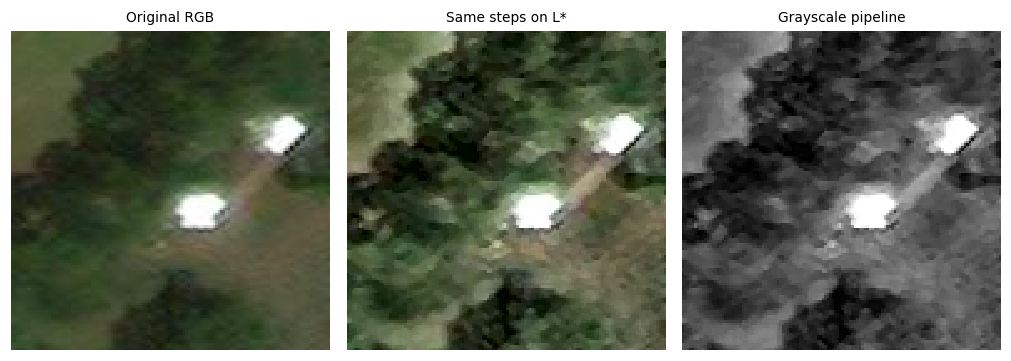

no_damage color reference versus luminance-enhanced color


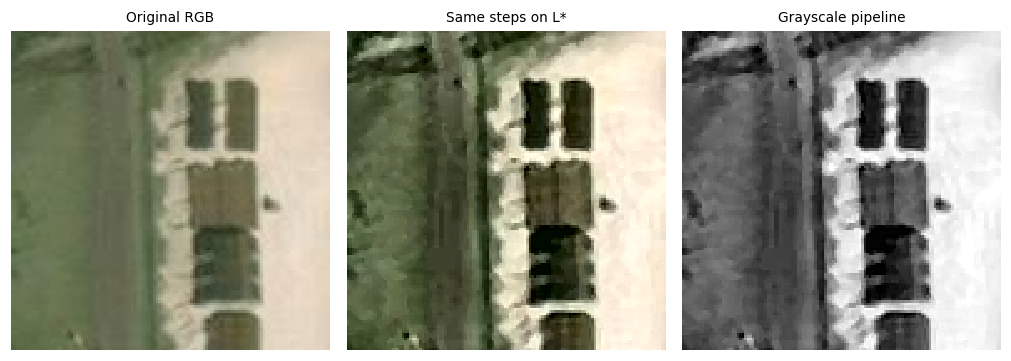

In [ ]:
# Color is retained for inspection by applying the same luminance steps to CIE L* and merging back.
# The measured pipeline stays grayscale, which matches Phase 2 and the tables above.
def enhance_color(rgb):
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    lab[:, :, 0] = full_output(lab[:, :, 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

for item in (annotated[0], annotated[7]):
    print(item['label'], 'color reference versus luminance-enhanced color')
    show_row(
        [item['rgb'], enhance_color(item['rgb']), full_output(item['gray'])],
        ['Original RGB', 'Same steps on L*', 'Grayscale pipeline'],
    )


### What the test results say

On all **40 test images**, mean orthogonal line length rises from **73.455** pixels on the original grayscale image to **135.917** after the full pipeline. Mean contrast SD rises from **29.310** to **59.373**, and saturation stays at **2.569%**. Edge density also rises, from **4.577%** to **17.155%**, and the fraction of those edges that lie on long lines falls from **0.157** to **0.107**. The pipeline finds more extended, building-aligned structure, and it also adds edges that are not part of those long lines.

The stage bars separate those two effects. Stretch and CLAHE account for most of the gain in aligned length (73.455 → 108.064 → 141.522). The 3×3 median then shortens that length to 104.297, and Laplacian sharpening restores it to 135.917, close to the CLAHE stage. Removing the median pushes orthogonal length to 216.713 and saturation to 5.172%. That larger line score was not selected: on the development set the bypass already clipped 5.852% of pixels and raised edge density to 25.281%.

Both classes move in the same direction. Damage patches go from orthogonal length **31.203** to **76.950**. No-damage patches go from **115.707** to **194.884**. Undamaged patches still contain more regular linear structure after enhancement. That gap is a description of the images, not a classifier and not a damage score.

On the **8 annotated test images**, recall of the traced boundaries rises from **0.560** on the original to **0.995** on the full pipeline. Precision falls from **0.184** to **0.128**, so F1 falls from **0.250** to **0.207**. Stretch alone reaches recall **0.772** and F1 **0.251**. The full pipeline’s advantage over stretch is the near-complete recovery of the traced lines, not a higher F1. The median bypass reaches recall **0.998** and F1 **0.159**: almost the same boundaries, with more detections away from the traces. Keeping the 3×3 median is consistent with that test comparison and with the development saturation limit.

**Color.** The same steps applied to CIE L* and merged back into the color image keep vegetation and water visible for a human reader. Grayscale remains the input to every number in the tables so the structural comparison has one luminance definition.

**Objective check against the project goal.** The goal was to make structural boundaries easier to detect. On a held-out region more than 30 km from the development region, traced-boundary recall and building-aligned line length both increase. The goal is met for visibility and detection of those boundaries. The goal is not met if it is read as “produce a cleaner edge map” or “classify damage.” F1 does not improve, edge maps contain vegetation and compression texture, and no damage decision is made.

**Artifacts and limits.** CLAHE can brighten tile boundaries and vegetation. Laplacian sharpening adds thin halos, which is why α stays at 0.10. Median filtering erases some thin lines before sharpening puts part of that length back. Canny still fires on tree texture and JPEG blocks. The traced reference is partial and small, so precision understates performance wherever a real boundary was not drawn. There is no official building mask in this release, and image-level labels cannot score pixel boundaries.


## 7. Challenges, changes since Phase 2, and conclusion

**Challenges.** The published folders repeat coordinates, so a random train/validation cut would not have been an independent test. The audit cell prints those repeat counts. Patches are only 128×128, and roofs are a few pixels wide, so a 5×5 median is enough to remove a building edge. There is no pixel-level building mask. Edge density, which was the easiest number to compute in Phase 2, increases even when many of the new edges are texture.

**Changes since Phase 2.**

- The evaluation sample is now 40 development images and 40 test images, with 8 traced test images. Phase 2 used 20 images for both tuning and reporting.
- Development and test regions are disjoint, duplicates are removed, and patches inside a set are at least 0.40 km apart. The minimum development–test distance printed above is greater than 30 km.
- Parameters were recomputed on the new development set. The frozen values match the Phase 2 provisional values: p = 1, CLAHE clip 2 and 8×8, median 3×3, α = 0.10, Canny 50/150, FFT D₀ = 10 as a side branch. The new evidence is what keeps them, including the explicit median-bypass comparison.
- Evaluation adds orthogonal line length and traced-boundary precision, recall, and F1. Edge density is still reported and is no longer treated as the result.

**What did not work as a success metric.** Raising clip, α, or lowering Canny thresholds increases line length and edge density together. Those settings were not adopted, because saturation and clutter rise with them. Passing the FFT detail map into Canny was already rejected in Phase 2 and was not revived. A damage classifier was not trained. Image-level accuracy would not answer whether a building boundary was found.

**Findings.** Contrast stretch and CLAHE do the useful work of revealing boundaries. Mild sharpening restores line length that the median removes, without the clipping of a strong Laplacian. The full pipeline almost doubles building-aligned line length on the test set and recovers nearly all traced reference boundaries. It does this while adding many non-boundary edges, so the edge map is more complete and less specific.

**Possible next steps.** Score the same pipeline against official building footprints if a mask release is available. Report recall at more than one tolerance. Keep a stricter Canny pair, 80/200, as an optional low-clutter output for patches that are mostly vegetation. A simple classifier on held-out labels could test whether the structural measurements help a damage decision; that is outside this checkpoint. Transfer learning was optional and is not part of this result.

## References

1. Group E, Phase 1 proposal, *Hurricane Damage Analysis and Image Enhancement Using Satellite Imagery*.
2. Group E, Phase 2 notebook and report, same title.
3. Kevin Mader, *Satellite Images of Hurricane Damage*, Kaggle, CC BY 4.0. <https://www.kaggle.com/datasets/kmader/satellite-images-of-hurricane-damage>
4. Chen et al. (2018), *Benchmark Dataset for Automatic Damaged Building Detection from Post-Hurricane Remotely Sensed Imagery*. <https://arxiv.org/abs/1812.05581>
5. OpenCV documentation for CLAHE, `medianBlur`, `Laplacian`, `GaussianBlur`, `Canny`, and `HoughLinesP`. <https://docs.opencv.org/4.x/>
